# 02 · Evaluación e imputación de concentraciones
Ejecutar después de `01_auditoria_preparacion.ipynb`, desde la raíz del proyecto.
El flujo es: comprobar datos → máscaras comunes → Mediana → selección interna de KNN/Iterative → evaluación externa → incertidumbre → aplicación y gráficos.

**Decisiones fijadas antes de calcular errores.** Se conservan los cinco bloques externos por perturbación del estudio ampliado anterior: se retira del entrenamiento el grupo completo (incluido WT). Cada consulta oculta **una medición**, manteniendo sus otros valores observados y sus faltantes naturales. No son cinco matrices con todas sus celdas borradas simultáneamente. Tres bloques internos repiten exactamente esa operación dentro del entrenamiento externo. El resultado evalúa reconstrucción individual en grupos nuevos; no demuestra desempeño ante todos los patrones conjuntos ni ante series analíticas nuevas. Las pruebas antiguas de patrones/series no se presentan como recalculadas.

El universo de intentos son todas las mediciones de los **20 compuestos homologados documentalmente**, incluso si luego el entrenamiento obliga a abstenerse. La elegibilidad se recalcula sin mirar los valores de prueba. A y B usan la intersección de variables elegibles en sus entrenamientos; así MMC2 no promueve por sí sola un compuesto con soporte insuficiente en Ishii. Las matrices finales conservan los 20 compuestos y 30 filas Ishii; MMC2 aporta entrenamiento, no verdades de evaluación.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.experimental import enable_iterative_imputer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.linear_model import BayesianRidge
from sklearn.metrics.pairwise import nan_euclidean_distances
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler

RAIZ = Path.cwd()
ENTRADA = RAIZ / 'auditoria'
SALIDA = RAIZ / 'evaluacion'
SALIDA.mkdir(exist_ok=True)
(SALIDA / 'figuras').mkdir(exist_ok=True)
SEMILLA = 20261109
SEMILLAS_POSTERIOR = list(range(1100, 1130))
METODOS = ['Mediana', 'KNN', 'Iterative']
CONFIGURACIONES = {
    'Mediana': [{}],
    'KNN': [dict(n_neighbors=3, weights='uniform'),
            dict(n_neighbors=5, weights='uniform'),
            dict(n_neighbors=7, weights='uniform'),
            dict(n_neighbors=3, weights='distance')],
    'Iterative': [dict(max_iter=50, tol=1e-3),
                  dict(max_iter=100, tol=1e-4)],
}
base = pd.read_csv(ENTRADA / 'panel_documental_mM.csv', index_col=0)
metadatos = pd.read_csv(ENTRADA / 'metadatos.csv', index_col=0)
referencias = pd.read_csv(ENTRADA / 'referencias_glucosa.csv', index_col=0)
ref = referencias.loc[base.columns, 'valor_mM']
ishii_ids = base.index[metadatos.loc[base.index, 'dataset_id'].eq('ISHII2007')]
mmc2_ids = base.index.difference(ishii_ids, sort=False)
ishii = base.loc[ishii_ids].copy()
mmc2 = base.loc[mmc2_ids].copy()
grupos = metadatos.grupo
assert base.shape == (38, 20) and ishii.shape == (30, 20)
assert base.index.is_unique and base.columns.is_unique
assert referencias.loc[base.columns, 'valida'].all()
assert ref.gt(0).all() and np.isfinite(ref).all()
assert referencias.loc[base.columns, 'SD_mM'].ge(0).all()
valores = base.to_numpy(dtype=float)
observados = valores[~np.isnan(valores)]
assert np.isfinite(observados).all(), "Hay concentraciones infinitas."
assert (observados >= 0).all(), "Hay concentraciones negativas."
panel = pd.read_csv(ENTRADA / 'elegibilidad.csv', index_col=0)
principales = panel.index[panel.panel_principal].tolist()
for escenario, original in [('A', ishii), ('B', base)]:
    auditada = pd.read_csv(ENTRADA / f'escenario_{escenario}_mM.csv', index_col=0)
    ratios = pd.read_csv(ENTRADA / f'escenario_{escenario}_R.csv', index_col=0)
    pd.testing.assert_frame_equal(auditada, original[principales], check_names=False)
    np.testing.assert_allclose(ratios, auditada.div(ref[principales]), equal_nan=True)
huellas_entrada = {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                   for p in ENTRADA.glob('*.csv')}
print('Ishii:', ishii.shape, '| MMC2:', mmc2.shape,
      '| observaciones documentales Ishii:', int(ishii.count().sum()))

Ishii: (30, 20) | MMC2: (8, 20) | observaciones documentales Ishii: 457


## 1. Elegibilidad y máscaras
Se reutilizan literalmente las reglas de la auditoría: ≥10 mediciones, ≥5 grupos, variación observable y ≥2 predictores con ≥5 pares medidos. Los compuestos con 5–9 valores son exploratorios; con 0–4, insuficientes. Estas reglas son filtros operativos de soporte, no una garantía de exactitud.

Las máscaras guardan muestra, compuesto, bloque y verdad original. La partición `GroupKFold` es determinista y no baraja grupos; la semilla se usa para los modelos. Un identificador por celda permite verificar que los seis análisis intentan exactamente las mismas posiciones. Las máscaras solo se reutilizan si su contenido y las huellas de entrada coinciden exactamente.

In [2]:
MIN_CANDIDATA = 10
MIN_EXPLORATORIA = 5
MIN_PREDICTORES = 2


def evaluar_elegibilidad(entrenamiento, grupos):
    """Recibe solo valores visibles del entrenamiento, nunca las verdades ocultas."""
    grupos = grupos.reindex(entrenamiento.index)
    assert grupos.notna().all()
    tabla = entrenamiento.count().rename('n_observados').to_frame()
    tabla['n_faltantes'] = entrenamiento.isna().sum()
    tabla['cobertura_pct'] = 100 * tabla.n_observados / len(entrenamiento)
    tabla['n_grupos'] = entrenamiento.notna().groupby(grupos).any().sum()
    tabla['n_valores_distintos'] = entrenamiento.nunique()
    tabla['clase'] = np.select(
        [tabla.n_observados < MIN_EXPLORATORIA,
         tabla.n_observados < MIN_CANDIDATA],
        ['insuficiente', 'exploratoria'], default='candidata_por_conteo',
    )
    basicas = tabla.index[
        (tabla.n_observados >= MIN_CANDIDATA)
        & (tabla.n_grupos >= MIN_EXPLORATORIA)
        & (tabla.n_valores_distintos >= 2)
    ]
    medidas = entrenamiento.notna().astype(int)
    coobservaciones = medidas.T @ medidas
    for metabolito in coobservaciones.columns:
        coobservaciones.at[metabolito, metabolito] = 0
    tabla['predictores_con_5_pares'] = (
        coobservaciones[basicas] >= MIN_EXPLORATORIA
    ).sum(axis=1)
    tabla['elegible'] = (
        tabla.index.isin(basicas)
        & tabla.predictores_con_5_pares.ge(MIN_PREDICTORES)
    )
    tabla['justificacion_datos'] = np.select(
        [tabla.n_observados < MIN_EXPLORATORIA,
         tabla.n_observados < MIN_CANDIDATA,
         tabla.n_grupos < MIN_EXPLORATORIA,
         tabla.n_valores_distintos < 2,
         tabla.predictores_con_5_pares < MIN_PREDICTORES],
        ['0-4 mediciones: conservar sin imputar',
         '5-9 mediciones: solo exploración',
         'Menos de cinco grupos representados',
         'Sin variación observable suficiente',
         'Menos de dos predictores con cinco pares medidos'],
        default='Soporte preliminar; falta validación del error',
    )
    return tabla

In [3]:
def construir_mascaras(ids, bloques):
    """Cada consulta oculta una celda de una muestra de un grupo retirado."""
    filas = []
    for bloque, (pos_train, pos_test) in enumerate(
        GroupKFold(bloques).split(ishii.loc[ids], groups=grupos.loc[ids])
    ):
        train_ids, test_ids = ids[pos_train], ids[pos_test]
        assert set(grupos.loc[train_ids]).isdisjoint(grupos.loc[test_ids])
        for muestra in test_ids:
            for metabolito in ishii.columns:
                verdad = ishii.at[muestra, metabolito]
                if pd.notna(verdad):
                    filas.append(dict(celda=f'{muestra}|{metabolito}',
                                      muestra=muestra, metabolito=metabolito,
                                      bloque=bloque, verdad_mM=float(verdad)))
    return pd.DataFrame(filas)


externas = construir_mascaras(ishii_ids, 5)
internas = {}
for bloque in range(5):
    test_ids = externas.loc[externas.bloque.eq(bloque), 'muestra'].unique()
    train_ids = ishii_ids[~ishii_ids.isin(test_ids)]
    internas[str(bloque)] = construir_mascaras(train_ids, 3)
internas['final'] = construir_mascaras(ishii_ids, 3)
assert externas.celda.is_unique
assert len(externas) == int(ishii.count().sum())
pd.testing.assert_frame_equal(externas, construir_mascaras(ishii_ids, 5))
mascaras = dict(entradas_sha256=huellas_entrada,
               externas=externas.to_dict('records'),
               internas={k: v.to_dict('records') for k, v in internas.items()})
archivo_mascaras = SALIDA / 'mascaras.json'
if archivo_mascaras.exists():
    assert json.loads(archivo_mascaras.read_text()) == mascaras, (
        'Las máscaras existentes no corresponden a estos datos; retirar resultados anteriores.'
    )
archivo_mascaras.write_text(json.dumps(mascaras, indent=2), encoding='utf-8')
display(externas.groupby('bloque').agg(celdas=('celda', 'size'),
                                     muestras=('muestra', 'nunique')))

,celdas,muestras
bloque,,
0,85,6
1,93,6
2,94,6
3,89,6
4,96,6


## 2. Un ajuste y sus predicciones
Esta función concentra la operación que se repite en cada bloque; no implementa ningún imputador propio. Recibe exclusivamente las filas de entrenamiento y las consultas ya definidas. La normalización usa la referencia externa fija. `StandardScaler` se ajusta solo en entrenamiento para KNN e Iterative; Mediana trabaja directamente en ratios. Sin logaritmos.

KNN considera 3, 5 o 7 vecinos y una alternativa ponderada por distancia. Se registra cuántos donantes tienen distancia definida: con menos de tres se rechaza la predicción; si hay ≥3 pero menos de k, se identifica la reducción automática de vecinos. No se acepta la sustitución por media que sklearn puede hacer cuando no hay distancias. La comprobación usa distancias de sklearn, no otro algoritmo KNN.

Iterative usa BayesianRidge porque regulariza regresiones con pocos datos y permite muestrear su predicción. Mantiene sus parámetros por defecto (registrados al final), no busca priors. Sus relaciones son lineales condicionales; regularización no corrige falta de información ni diferencias de estudio. `skip_complete=False` permite aprender objetivos completos en entrenamiento que se ocultan en prueba. El límite inferior en unidades estandarizadas equivale a 0 mM.

Mediana es siempre una **sustitución general del entrenamiento**. Los métodos multivariados requieren ≥2 predictores originales visibles por consulta; un dato que otro paso imputó no cuenta como evidencia observada. Se registran advertencias y rondas de Iterative. Si no converge, se conserva su estimación para evaluar el algoritmo tal como se ejecutó, con advertencia explícita; no hay rescate silencioso por otro método.

In [4]:
registro_ajustes = []
registro_elegibilidad = []


def ajustar_predecir(train_ids, consultas, escenario, metodo, parametros,
                     etapa, bloque, semilla=SEMILLA, posterior=False):
    """Ajusta exclusivamente con entrenamiento y conserva todas las abstenciones."""
    entrenamiento_a = ishii.loc[train_ids]
    entrenamiento_b = pd.concat([entrenamiento_a, mmc2])
    tabla_a = evaluar_elegibilidad(entrenamiento_a, grupos)
    tabla_b = evaluar_elegibilidad(entrenamiento_b, grupos)
    columnas = tabla_a.index[tabla_a.elegible & tabla_b.elegible].tolist()
    entrenamiento = entrenamiento_a if escenario == 'A' else entrenamiento_b
    assert set(train_ids).issubset(ishii_ids)
    if etapa != 'final':
        assert set(consultas.muestra).isdisjoint(train_ids)
        assert set(grupos.loc[consultas.muestra]).isdisjoint(grupos.loc[train_ids])
    registro_elegibilidad.extend(
        dict(etapa=etapa, bloque=bloque, escenario=escenario,
             metabolito=m, elegible=m in columnas,
             n_ishii=int(tabla_a.at[m, 'n_observados']),
             n_entrenamiento=int(entrenamiento[m].count()))
        for m in ishii.columns
    )
    resultado = consultas.copy().reset_index(drop=True)
    resultado['escenario'] = escenario
    resultado['metodo'] = metodo
    resultado['pred_mM'] = np.nan
    resultado['motivo'] = 'objetivo_no_elegible_en_entrenamiento'
    resultado['soporte'] = 'sin_estimacion'
    resultado['n_predictores_observados'] = 0
    resultado['n_donantes_distancia'] = np.nan
    resultado['vecinos_utilizables'] = np.nan
    if not columnas:
        return resultado
    if etapa == 'final':
        # Una fila por muestra: cada sorteo final es una imputación conjunta coherente.
        consultas_r = ishii.loc[resultado.muestra.unique(), columnas].copy()
        posiciones = {muestra: i for i, muestra in enumerate(consultas_r.index)}
        filas_consulta = resultado.muestra.map(posiciones).to_numpy()
        consultas_r.index = range(len(consultas_r))
    else:
        consultas_r = ishii.loc[resultado.muestra, columnas].copy()
        consultas_r.index = resultado.index
        filas_consulta = resultado.index.to_numpy()
        for i, fila in resultado.iterrows():
            if fila.metabolito in columnas:
                consultas_r.at[i, fila.metabolito] = np.nan
    consultas_r = consultas_r.div(ref[columnas])
    train_r = entrenamiento[columnas].div(ref[columnas])
    if metodo == 'Mediana':
        modelo = SimpleImputer(strategy='median')
        x_train, x_query = train_r.to_numpy(), consultas_r.to_numpy()
        escalador = None
    else:
        escalador = StandardScaler().fit(train_r)
        x_train = escalador.transform(train_r)
        x_query = escalador.transform(consultas_r)
        if metodo == 'KNN':
            modelo = KNNImputer(**parametros)
        else:
            modelo = IterativeImputer(
                estimator=BayesianRidge(), initial_strategy='median',
                imputation_order='ascending', sample_posterior=posterior,
                skip_complete=False, random_state=semilla,
                min_value=-escalador.mean_ / escalador.scale_, **parametros,
            )
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always')
        modelo.fit(x_train)
        predicciones = modelo.transform(x_query)
    if escalador is not None:
        predicciones = escalador.inverse_transform(predicciones)
    predicciones = predicciones * ref[columnas].to_numpy()
    no_converge = any(issubclass(a.category, ConvergenceWarning) for a in avisos)
    registro_ajustes.append(dict(
        etapa=etapa, bloque=bloque, escenario=escenario, metodo=metodo,
        parametros=json.dumps(parametros, sort_keys=True), semilla=semilla,
        posterior=posterior, n_train=len(entrenamiento), n_variables=len(columnas),
        columnas='|'.join(columnas), rondas=getattr(modelo, 'n_iter_', None),
        parada_convergencia_aplica=metodo == 'Iterative' and not posterior,
        aviso_convergencia=no_converge,
        avisos=' | '.join(sorted(set(str(a.message) for a in avisos))),
    ))
    distancias = nan_euclidean_distances(x_query, x_train) if metodo == 'KNN' else None
    for i, fila in resultado.iterrows():
        objetivo = fila.metabolito
        if objetivo not in columnas:
            continue
        j = columnas.index(objetivo)
        fila_consulta = filas_consulta[i]
        n_predictores = int(consultas_r.loc[fila_consulta].count())
        resultado.at[i, 'n_predictores_observados'] = n_predictores
        if metodo != 'Mediana' and n_predictores < 2:
            resultado.at[i, 'motivo'] = 'menos_de_dos_predictores_medidos'
            continue
        if metodo == 'KNN':
            donantes = np.isfinite(distancias[fila_consulta]) & np.isfinite(x_train[:, j])
            n_donantes = int(donantes.sum())
            resultado.at[i, 'n_donantes_distancia'] = n_donantes
            resultado.at[i, 'vecinos_utilizables'] = min(n_donantes, parametros['n_neighbors'])
            if n_donantes < 3:
                resultado.at[i, 'motivo'] = 'menos_de_tres_donantes_con_distancia'
                continue
        valor = float(predicciones[fila_consulta, j])
        if not np.isfinite(valor) or valor < -1e-12:
            resultado.at[i, 'motivo'] = 'prediccion_no_finita_o_negativa'
            continue
        resultado.at[i, 'pred_mM'] = max(0.0, valor)
        resultado.at[i, 'motivo'] = 'estimado'
        resultado.at[i, 'soporte'] = (
            'sustitucion_general_mediana' if metodo == 'Mediana'
            else 'multivariado_con_observaciones'
        )
    return resultado

## 3. Primero verificar Mediana
La prueba compara cada predicción con la mediana directa del entrenamiento admisible. Comprueba además que las verdades evaluadas son originales y que la matriz de entrada sigue intacta.

In [5]:
medianas = []
original = ishii.copy(deep=True)
for bloque in range(5):
    consultas = externas[externas.bloque.eq(bloque)]
    train_ids = ishii_ids[~ishii_ids.isin(consultas.muestra)]
    for escenario in ['A', 'B']:
        pred = ajustar_predecir(train_ids, consultas, escenario, 'Mediana', {},
                                'externa', bloque)
        train = ishii.loc[train_ids] if escenario == 'A' else pd.concat([ishii.loc[train_ids], mmc2])
        for fila in pred[pred.pred_mM.notna()].itertuples():
            assert np.isclose(fila.pred_mM, train[fila.metabolito].median())
            assert fila.verdad_mM == ishii.at[fila.muestra, fila.metabolito]
        medianas.append(pred)
pd.testing.assert_frame_equal(ishii, original)
print('Mediana: máscaras, exclusión de grupos, valores y reconstrucción comprobados.')

Mediana: máscaras, exclusión de grupos, valores y reconstrucción comprobados.


## 4. Selección interna y evaluación externa
Para cada método y escenario se elige **una configuración global**, no una por compuesto. El criterio interno es MAE_R macro: primero se promedian errores por metabolito y después entre metabolitos, con el mismo peso por compuesto. Las configuraciones se comparan solo en las celdas donde todas respondieron. Los empates favorecen la primera configuración, más sencilla. Se guardan también cobertura y número de compuestos; una cobertura mayor no reduce artificialmente el error.

La elección final se hace mediante tres bloques sobre todo el entrenamiento disponible, después de terminar la evaluación externa; no se escoge la mejor configuración mirando sus verdades externas. Las predicciones externas se calculan una sola vez con la configuración seleccionada dentro de su bloque.

In [6]:
registro_busqueda = []
seleccionados = []


def seleccionar_parametros(ids, mascaras_internas, escenario, metodo, bloque_externo):
    """Compara la cuadrícula pequeña solo en las verdades internas."""
    predicciones = []
    for numero, parametros in enumerate(CONFIGURACIONES[metodo]):
        for interno in range(3):
            consulta = mascaras_internas[mascaras_internas.bloque.eq(interno)]
            train_ids = ids[~ids.isin(consulta.muestra)]
            pred = ajustar_predecir(
                train_ids, consulta, escenario, metodo, parametros,
                'interna', f'{bloque_externo}.{interno}',
            )
            pred['configuracion'] = numero
            predicciones.append(pred)
    tabla = pd.concat(predicciones, ignore_index=True)
    comunes = tabla.pivot(index='celda', columns='configuracion', values='pred_mM').notna().all(axis=1)
    celdas = comunes.index[comunes]
    assert len(celdas) > 0, 'No hay soporte interno común; no declarar una selección validada.'
    errores = []
    for numero, parametros in enumerate(CONFIGURACIONES[metodo]):
        filas = tabla[(tabla.configuracion == numero) & tabla.celda.isin(celdas)].copy()
        filas['error_R'] = (filas.pred_mM - filas.verdad_mM).abs() / filas.metabolito.map(ref)
        mae = filas.groupby('metabolito').error_R.mean().mean()
        errores.append(mae)
        registro_busqueda.append(dict(
            bloque_externo=bloque_externo, escenario=escenario, metodo=metodo,
            configuracion=numero, parametros=json.dumps(parametros, sort_keys=True),
            MAE_R_macro=float(mae), n_comunes=len(filas),
            n_metabolitos=filas.metabolito.nunique(),
            n_intentos=len(mascaras_internas),
            n_predicciones=int(tabla.loc[tabla.configuracion.eq(numero), 'pred_mM'].count()),
        ))
    elegido = int(np.argmin(errores))
    parametros = CONFIGURACIONES[metodo][elegido].copy()
    seleccionados.append(dict(bloque_externo=bloque_externo, escenario=escenario,
                             metodo=metodo, configuracion=elegido,
                             parametros=json.dumps(parametros, sort_keys=True)))
    return parametros


predicciones_externas = list(medianas)
parametros_externos = {}
for metodo in ['KNN', 'Iterative']:
    for bloque in range(5):
        consultas = externas[externas.bloque.eq(bloque)]
        train_ids = ishii_ids[~ishii_ids.isin(consultas.muestra)]
        for escenario in ['A', 'B']:
            parametros = seleccionar_parametros(
                train_ids, internas[str(bloque)], escenario, metodo, bloque,
            )
            parametros_externos[(bloque, escenario, metodo)] = parametros
            pred = ajustar_predecir(train_ids, consultas, escenario, metodo,
                                    parametros, 'externa', bloque)
            predicciones_externas.append(pred)
        print(metodo, 'bloque externo', bloque + 1, 'terminado', flush=True)
validacion = pd.concat(predicciones_externas, ignore_index=True)
validacion['error_mM'] = (validacion.pred_mM - validacion.verdad_mM).abs()
validacion['error_R'] = validacion.error_mM / validacion.metabolito.map(ref)
assert not validacion.duplicated(['celda', 'metodo', 'escenario']).any()
assert len(validacion) == 6 * len(externas)
for _, filas in validacion.groupby(['escenario', 'metodo']):
    assert set(filas.celda) == set(externas.celda)
assert (validacion.verdad_mM == validacion.celda.map(externas.set_index('celda').verdad_mM)).all()
pd.testing.assert_frame_equal(ishii, original)
validacion.to_csv(SALIDA / 'validacion_celdas.csv', index=False)
print('Validación determinista comprobada; se puede continuar con incertidumbre.')

KNN bloque externo 1 terminado
KNN bloque externo 2 terminado
KNN bloque externo 3 terminado
KNN bloque externo 4 terminado
KNN bloque externo 5 terminado
Iterative bloque externo 1 terminado
Iterative bloque externo 2 terminado
Iterative bloque externo 3 terminado
Iterative bloque externo 4 terminado
Iterative bloque externo 5 terminado
Validación determinista comprobada; se puede continuar con incertidumbre.


## 5. Error, cobertura y comparación sobre las mismas celdas
Se conservan dos lecturas: todos los resultados disponibles y la intersección de celdas con predicción de **los tres métodos en ambos escenarios**. La segunda es la comparación principal. Las tablas por bloque permiten ver variación; su desviación estándar no es un intervalo de confianza (los entrenamientos se solapan).

MAE micro da igual peso a cada celda; MAE macro da igual peso a cada metabolito con predicción. El denominador de cobertura siempre incluye todos los intentos documentales, incluidos los excluidos. MAE_mM mezcla escalas de compuestos y por eso no se usa para seleccionar parámetros. El panel original de siete tenía otras máscaras y reglas: sus MAE anteriores no se comparan numéricamente con estos como si el único cambio fuera ampliar el panel.

In [7]:
comunes = validacion.pivot(index='celda', columns=['escenario', 'metodo'], values='pred_mM').notna().all(axis=1)
celdas_comunes = comunes.index[comunes]
validacion['comun_seis'] = validacion.celda.isin(celdas_comunes)
metricas = []
for alcance in ['disponibles', 'comunes_seis']:
    tabla = validacion.copy()
    if alcance == 'comunes_seis':
        tabla.loc[~tabla.comun_seis, ['error_mM', 'error_R', 'pred_mM']] = np.nan
    for columnas, nivel in [(['escenario', 'metodo', 'metabolito'], 'metabolito'),
                            (['escenario', 'metodo', 'bloque', 'metabolito'], 'bloque_metabolito')]:
        resumen = tabla.groupby(columnas).agg(
            n_intentos=('celda', 'size'), n_predicciones=('pred_mM', 'count'),
            MAE_mM=('error_mM', 'mean'), MAE_R=('error_R', 'mean'),
        ).reset_index()
        resumen['cobertura_pct'] = 100 * resumen.n_predicciones / resumen.n_intentos
        resumen['alcance'], resumen['nivel'] = alcance, nivel
        metricas.append(resumen)
metricas = pd.concat(metricas, ignore_index=True)
metricas.to_csv(SALIDA / 'metricas.csv', index=False)
resumen_global = []
for alcance in ['disponibles', 'comunes_seis']:
    tabla = validacion if alcance == 'disponibles' else validacion[validacion.comun_seis]
    for (escenario, metodo), filas in tabla.groupby(['escenario', 'metodo']):
        por_met = filas.groupby('metabolito')[['error_mM', 'error_R']].mean()
        por_bloque = filas.groupby(['bloque', 'metabolito']).error_R.mean().groupby('bloque').mean()
        resumen_global.append(dict(
            alcance=alcance, escenario=escenario, metodo=metodo,
            n_intentos=len(externas), n_predicciones=int(filas.pred_mM.count()),
            n_metabolitos=int(por_met.error_R.count()),
            cobertura_pct=100 * filas.pred_mM.count() / len(externas),
            MAE_R_macro=por_met.error_R.mean(), MAE_mM_macro=por_met.error_mM.mean(),
            MAE_R_micro=filas.error_R.mean(), MAE_mM_micro=filas.error_mM.mean(),
            SD_MAE_R_macro_bloques=por_bloque.std(ddof=1),
        ))
resumen_global = pd.DataFrame(resumen_global)
resumen_global.to_csv(SALIDA / 'resumen_global.csv', index=False)
validacion.to_csv(SALIDA / 'validacion_celdas.csv', index=False)
display(resumen_global.round(4))
display(validacion.groupby(['escenario', 'metodo', 'motivo']).size().rename('celdas').to_frame())

,alcance,escenario,metodo,n_intentos,n_predicciones,n_metabolitos,cobertura_pct,MAE_R_macro,MAE_mM_macro,MAE_R_micro,MAE_mM_micro,SD_MAE_R_macro_bloques
0,disponibles,A,Iterative,457,416,16,91.0284,0.4713,0.0867,0.5340,0.0940,0.0842
1,disponibles,A,KNN,457,416,16,91.0284,0.4801,0.0910,0.5451,0.0991,0.1210
2,disponibles,A,Mediana,457,416,16,91.0284,0.6587,0.1216,0.7508,0.1349,0.1177
3,disponibles,B,Iterative,457,416,16,91.0284,0.4956,0.1207,0.5351,0.1114,0.1006
4,disponibles,B,KNN,457,416,16,91.0284,0.4835,0.0853,0.5487,0.0925,0.0907
5,disponibles,B,Mediana,457,416,16,91.0284,0.7009,0.1280,0.7971,0.1411,0.1307
6,comunes_seis,A,Iterative,457,416,16,91.0284,0.4713,0.0867,0.5340,0.0940,0.0842
7,comunes_seis,A,KNN,457,416,16,91.0284,0.4801,0.0910,0.5451,0.0991,0.1210
8,comunes_seis,A,Mediana,457,416,16,91.0284,0.6587,0.1216,0.7508,0.1349,0.1177
9,comunes_seis,B,Iterative,457,416,16,91.0284,0.4956,0.1207,0.5351,0.1114,0.1006


celdas
escenario metodo    motivo                                       
A         Iterative estimado                                  416
                    objetivo_no_elegible_en_entrenamiento      41
          KNN       estimado                                  416
                    objetivo_no_elegible_en_entrenamiento      41
          Mediana   estimado                                  416
                    objetivo_no_elegible_en_entrenamiento      41
B         Iterative estimado                                  416
                    objetivo_no_elegible_en_entrenamiento      41
          KNN       estimado                                  416
                    objetivo_no_elegible_en_entrenamiento      41
          Mediana   estimado                                  416
                    objetivo_no_elegible_en_entrenamiento      41

## 6. Configuración de aplicación y criterio para completar huecos
Se vuelven a seleccionar parámetros por validación interna de tres bloques usando los 30 Ishii (más MMC2 en B). Para la aplicación se exige además evidencia externa: **al menos diez predicciones en al menos tres bloques** para el metabolito/método/escenario. Es un umbral operativo conservador de evaluabilidad, no prueba de precisión suficiente. Se aplica a todos los métodos antes de rellenar; una estimación puede tener soporte y aun así tener error alto.

No se descarta un método solo porque haya perdido contra otro: se entregan matrices separadas para compararlos y se recomienda el de menor MAE_R macro común. No hay un umbral biológico de error aceptable aportado por las fuentes, por lo que ninguna matriz se etiqueta como verdad validada. Los compuestos sin evaluación suficiente permanecen incompletos. Las filas naturalmente incompletas no se evalúan contra valores inventados.

In [8]:
parametros_finales = {}
for escenario in ['A', 'B']:
    parametros_finales[(escenario, 'Mediana')] = {}
    for metodo in ['KNN', 'Iterative']:
        parametros_finales[(escenario, metodo)] = seleccionar_parametros(
            ishii_ids, internas['final'], escenario, metodo, 'final',
        )
soporte_externo = validacion[validacion.pred_mM.notna()].groupby(
    ['escenario', 'metodo', 'metabolito']
).agg(n_evaluadas=('celda', 'size'), n_bloques=('bloque', 'nunique'))
soporte_externo['habilita_aplicacion'] = (
    soporte_externo.n_evaluadas.ge(10) & soporte_externo.n_bloques.ge(3)
)
soporte_externo.to_csv(SALIDA / 'soporte_aplicacion.csv')
huecos = []
for muestra in ishii.index:
    for metabolito in ishii.columns:
        if pd.isna(ishii.at[muestra, metabolito]):
            huecos.append(dict(celda=f'{muestra}|{metabolito}', muestra=muestra,
                               metabolito=metabolito, bloque='final', verdad_mM=np.nan))
huecos = pd.DataFrame(huecos)
assert len(huecos) == int(ishii.isna().sum().sum())

## 7. Incertidumbre: etapa adicional, sin búsqueda posterior
La evaluación determinista anterior ya terminó. Ahora se hacen **30 ajustes independientes por escenario y bloque externo**, con las configuraciones Iterative seleccionadas previamente, y 30 ajustes por escenario para los huecos reales. No se repiten los bloques internos ni la búsqueda de parámetros. Las semillas se comparten entre A/B para trazabilidad, sin afirmar que sus sorteos sean idénticos.

`sample_posterior=True` usa la desviación predictiva de BayesianRidge. En sklearn 1.8, la parada temprana solo aplica sin posterior: cada ajuste ejecuta explícitamente las 50 o 100 rondas seleccionadas. Se comprueba en el registro. Los cuantiles de 30 valores son aproximaciones Monte Carlo; **no** incluyen toda la variabilidad biológica ni la incertidumbre de la referencia de glucosa o del volumen 2.3 mL/gCDW. Baja SD no implica bajo error.

Se guardan sorteos incluso para candidatos que finalmente se abstienen por evaluación insuficiente, con una etiqueta de habilitación. Esto permite estudiar incertidumbre sin rellenar indebidamente la matriz final. La cobertura de intervalos tiene dos denominadores: entre intervalos emitidos y entre todos los intentos. La segunda no es cobertura nominal del intervalo, sino disponibilidad más inclusión del valor real.

Referencias: [IterativeImputer 1.8](https://scikit-learn.org/1.8/modules/generated/sklearn.impute.IterativeImputer.html), [KNNImputer](https://scikit-learn.org/1.8/modules/generated/sklearn.impute.KNNImputer.html), [BayesianRidge](https://scikit-learn.org/1.8/modules/generated/sklearn.linear_model.BayesianRidge.html).

In [9]:
sorteos = []
for etapa in ['externa', 'final']:
    bloques = range(5) if etapa == 'externa' else ['final']
    for bloque in bloques:
        consulta = externas[externas.bloque.eq(bloque)] if etapa == 'externa' else huecos
        train_ids = ishii_ids[~ishii_ids.isin(consulta.muestra)] if etapa == 'externa' else ishii_ids
        for escenario in ['A', 'B']:
            parametros = (parametros_externos[(bloque, escenario, 'Iterative')]
                          if etapa == 'externa' else parametros_finales[(escenario, 'Iterative')])
            for repeticion, semilla in enumerate(SEMILLAS_POSTERIOR):
                pred = ajustar_predecir(
                    train_ids, consulta, escenario, 'Iterative', parametros,
                    etapa, bloque, semilla=semilla, posterior=True,
                )
                pred['etapa'], pred['repeticion'], pred['semilla'] = etapa, repeticion, semilla
                sorteos.append(pred[['etapa', 'bloque', 'celda', 'muestra', 'metabolito',
                                     'escenario', 'verdad_mM', 'pred_mM', 'motivo',
                                     'repeticion', 'semilla']])
            print('Posterior:', etapa, bloque, escenario, '30 ajustes terminados', flush=True)
sorteos = pd.concat(sorteos, ignore_index=True)
assert sorteos.groupby(['etapa', 'escenario', 'celda']).size().eq(30).all()
incertidumbre = sorteos.groupby(
    ['etapa', 'escenario', 'bloque', 'celda', 'muestra', 'metabolito'], sort=False,
).agg(n_sorteos=('pred_mM', 'count'), media_mM=('pred_mM', 'mean'),
      SD_mM=('pred_mM', 'std'),
      q025_mM=('pred_mM', lambda x: x.quantile(.025)),
      q975_mM=('pred_mM', lambda x: x.quantile(.975)),
      verdad_mM=('verdad_mM', 'first')).reset_index()
incertidumbre['amplitud_mM'] = incertidumbre.q975_mM - incertidumbre.q025_mM
incertidumbre['amplitud_R'] = incertidumbre.amplitud_mM / incertidumbre.metabolito.map(ref)
incertidumbre['intervalo_disponible'] = incertidumbre.n_sorteos.eq(30)
incertidumbre['contiene_verdad'] = np.where(
    incertidumbre.verdad_mM.notna() & incertidumbre.intervalo_disponible,
    incertidumbre.verdad_mM.between(incertidumbre.q025_mM, incertidumbre.q975_mM), np.nan,
)
incertidumbre['sesgo_mM'] = incertidumbre.media_mM - incertidumbre.verdad_mM
incertidumbre['habilita_aplicacion'] = [
    bool(soporte_externo.habilita_aplicacion.get((r.escenario, 'Iterative', r.metabolito), False))
    for r in incertidumbre.itertuples()
]
cobertura_intervalos = incertidumbre[incertidumbre.etapa.eq('externa')].groupby(
    ['escenario', 'metabolito']
).agg(n_intentos=('celda', 'size'), n_intervalos=('contiene_verdad', 'count'),
      cobertura_entre_intervalos=('contiene_verdad', 'mean'),
      n_cubiertos=('contiene_verdad', 'sum'), amplitud_media_mM=('amplitud_mM', 'mean'),
      amplitud_media_R=('amplitud_R', 'mean'), sesgo_medio_mM=('sesgo_mM', 'mean'))
cobertura_intervalos['disponibilidad_pct'] = 100 * cobertura_intervalos.n_intervalos / cobertura_intervalos.n_intentos
cobertura_intervalos['cubiertos_sobre_intentos_pct'] = 100 * cobertura_intervalos.n_cubiertos / cobertura_intervalos.n_intentos
sorteos.to_csv(SALIDA / 'sorteos_posteriores.csv.gz', index=False, compression='gzip')
incertidumbre.to_csv(SALIDA / 'incertidumbre.csv', index=False)
cobertura_intervalos.to_csv(SALIDA / 'cobertura_intervalos.csv')
display(cobertura_intervalos.round(3))

Posterior: externa 0 A 30 ajustes terminados
Posterior: externa 0 B 30 ajustes terminados
Posterior: externa 1 A 30 ajustes terminados
Posterior: externa 1 B 30 ajustes terminados
Posterior: externa 2 A 30 ajustes terminados
Posterior: externa 2 B 30 ajustes terminados
Posterior: externa 3 A 30 ajustes terminados
Posterior: externa 3 B 30 ajustes terminados
Posterior: externa 4 A 30 ajustes terminados
Posterior: externa 4 B 30 ajustes terminados
Posterior: final final A 30 ajustes terminados
Posterior: final final B 30 ajustes terminados


n_intentos  n_intervalos  cobertura_entre_intervalos  \
escenario metabolito                                                         
A         ade                 30            30                       0.900   
          adp                 30            30                       0.933   
          akg                 11             0                         NaN   
          amp                 30            30                       0.900   
          atp                 30            30                       0.933   
          cAMP                29            29                       0.897   
          cit                 12             2                       1.000   
          dhap                 8             0                         NaN   
          fum                 23            23                       0.870   
          gdp                 30            30                       0.933   
          gmp                 30            30                       0.833   
          gtp                 30            30                       0.867   
          nad                 30            30                       0.933   
          nadh                 6             0                         NaN   
          nadp                30            30                       0.933   
          nadph                6             0                         NaN   
          pep                 22            22                       0.818   
          pyr                 14            14                       0.857   
          s7p                 29            29                       0.897   
          succ                27            27                       0.815   
B         ade                 30            30                       0.833   
          adp                 30            30                       0.967   
          akg                 11             0                         NaN   
          amp                 30            30                       0.833   
          atp                 30            30                       0.933   
          cAMP                29            29                       0.862   
          cit                 12             2                       0.500   
          dhap                 8             0                         NaN   
          fum                 23            23                       0.522   
          gdp                 30            30                       0.933   
          gmp                 30            30                       1.000   
          gtp                 30            30                       0.833   
          nad                 30            30                       1.000   
          nadh                 6             0                         NaN   
          nadp                30            30                       0.933   
          nadph                6             0                         NaN   
          pep                 22            22                       0.818   
          pyr                 14            14                       0.786   
          s7p                 29            29                       0.724   
          succ                27            27                       0.926   

                      n_cubiertos  amplitud_media_mM  amplitud_media_R  \
escenario metabolito                                                     
A         ade                27.0              0.166            12.240   
          adp                28.0              0.348             0.576   
          akg                 0.0                NaN               NaN   
          amp                27.0              0.450             0.932   
          atp                28.0              1.094             0.317   
          cAMP               26.0              0.007             4.009   
          cit                 2.0              0.026             0.038   
          dhap                0.0                NaN               NaN   
     

## 8. Aplicar los tres métodos a los candidatos
Cada matriz se inicia como una copia de los datos originales. Solo se asignan predicciones a posiciones originalmente vacías y con soporte de entrenamiento, consulta y evaluación externa. Mediana conserva su etiqueta de sustitución general. Las salidas finales son deterministas; las medias posteriores se entregan aparte, sin reemplazar silenciosamente a Iterative determinista.

In [10]:
matrices = {}
imputaciones = []
for escenario in ['A', 'B']:
    for metodo in METODOS:
        pred = ajustar_predecir(ishii_ids, huecos, escenario, metodo,
                                parametros_finales[(escenario, metodo)], 'final', 'final')
        pred['candidato_mM'] = pred.pred_mM
        for i, fila in pred.iterrows():
            habilita = soporte_externo.habilita_aplicacion.get(
                (escenario, metodo, fila.metabolito), False,
            )
            if pd.notna(fila.pred_mM) and not habilita:
                pred.at[i, 'pred_mM'] = np.nan
                pred.at[i, 'motivo'] = 'evaluacion_externa_insuficiente'
        matriz = ishii.copy()
        for fila in pred[pred.pred_mM.notna()].itertuples():
            assert pd.isna(ishii.at[fila.muestra, fila.metabolito])
            matriz.at[fila.muestra, fila.metabolito] = fila.pred_mM
        assert matriz.shape == ishii.shape
        pd.testing.assert_frame_equal(matriz.where(ishii.notna()), ishii)
        excluidos = panel.index[~panel.panel_principal]
        pd.testing.assert_frame_equal(matriz[excluidos], ishii[excluidos])
        matrices[(escenario, metodo)] = matriz
        matriz.to_csv(SALIDA / f'matriz_{escenario}_{metodo}_mM.csv')
        imputaciones.append(pred)
imputaciones = pd.concat(imputaciones, ignore_index=True)
imputaciones.to_csv(SALIDA / 'imputaciones.csv', index=False)
display(imputaciones.groupby(['escenario', 'metodo', 'motivo']).size().rename('celdas').to_frame())

celdas
escenario metodo    motivo                                       
A         Iterative estimado                                   36
                    evaluacion_externa_insuficiente            37
                    objetivo_no_elegible_en_entrenamiento      70
          KNN       estimado                                   36
                    evaluacion_externa_insuficiente            37
                    objetivo_no_elegible_en_entrenamiento      70
          Mediana   estimado                                   36
                    evaluacion_externa_insuficiente            37
                    objetivo_no_elegible_en_entrenamiento      70
B         Iterative estimado                                   36
                    evaluacion_externa_insuficiente            37
                    objetivo_no_elegible_en_entrenamiento      70
          KNN       estimado                                   36
                    evaluacion_externa_insuficiente            37
                    objetivo_no_elegible_en_entrenamiento      70
          Mediana   estimado                                   36
                    evaluacion_externa_insuficiente            37
                    objetivo_no_elegible_en_entrenamiento      70

## 9. Descriptivos en las mismas 30 muestras
La SD es muestral (`ddof=1`); IQR = Q75−Q25. CV = SD/media se deja indefinido con menos de dos valores o media no positiva/casi cero. Es descriptivo, no una medida de calidad de imputación. Hay dos comparaciones: datos disponibles de cada matriz y solo los huecos que completaron los seis análisis. En ambos se conservan todas las mediciones originales.

In [11]:
comun_imputacion = imputaciones.pivot(index='celda', columns=['escenario', 'metodo'], values='pred_mM').notna().all(axis=1)
casillas_comunes = set(comun_imputacion.index[comun_imputacion])
estadisticos = []
for alcance in ['disponibles', 'comunes_seis']:
    conjuntos = {('original', 'observado'): ishii}
    for clave, matriz in matrices.items():
        comparada = matriz.copy()
        if alcance == 'comunes_seis':
            for fila in huecos.itertuples():
                if fila.celda not in casillas_comunes:
                    comparada.at[fila.muestra, fila.metabolito] = np.nan
        conjuntos[clave] = comparada
    for (escenario, metodo), matriz in conjuntos.items():
        for metabolito in ishii.columns:
            x = matriz[metabolito].dropna()
            n, media, sd = len(x), x.mean(), x.std(ddof=1)
            cv_valido = n >= 2 and np.isfinite(media) and media > 1e-12
            n_obs = int(ishii[metabolito].count())
            estadisticos.append(dict(
                alcance=alcance, escenario=escenario, metodo=metodo, metabolito=metabolito,
                observados=n_obs, imputados=n - n_obs, pendientes=30 - n,
                imputados_pct=100 * (n - n_obs) / 30,
                media_mM=media, mediana_mM=x.median(), SD_mM=sd,
                IQR_mM=x.quantile(.75) - x.quantile(.25),
                CV=sd / media if cv_valido else np.nan,
                CV_interpretable=cv_valido,
                motivo_CV='' if cv_valido else 'n<2 o media no positiva/casi cero',
            ))
estadisticos = pd.DataFrame(estadisticos)
estadisticos.to_csv(SALIDA / 'estadisticos.csv', index=False)
print('Huecos completados por los seis análisis:', len(casillas_comunes))
display(estadisticos.query("alcance == 'disponibles' and escenario == 'A'") .round(4))

Huecos completados por los seis análisis: 36


,alcance,escenario,metodo,metabolito,observados,imputados,pendientes,imputados_pct,media_mM,mediana_mM,SD_mM,IQR_mM,CV,CV_interpretable,motivo_CV
20,disponibles,A,Mediana,pyr,14,16,0,53.3333,0.2309,0.2385,0.0640,0.0000,0.2773,True,
21,disponibles,A,Mediana,fum,23,7,0,23.3333,0.0586,0.0563,0.0190,0.0182,0.3241,True,
22,disponibles,A,Mediana,succ,27,3,0,10.0000,0.0777,0.0686,0.0291,0.0283,0.3742,True,
23,disponibles,A,Mediana,akg,11,0,19,0.0000,0.0525,0.0481,0.0218,0.0097,0.4148,True,
24,disponibles,A,Mediana,pep,22,8,0,26.6667,0.0801,0.0737,0.0527,0.0241,0.6580,True,
25,disponibles,A,Mediana,dhap,8,0,22,0.0000,0.0447,0.0278,0.0494,0.0644,1.1043,True,
26,disponibles,A,Mediana,s7p,29,1,0,3.3333,0.3419,0.1800,0.5377,0.1327,1.5730,True,
27,disponibles,A,Mediana,ade,30,0,0,0.0000,0.1069,0.0924,0.0593,0.0959,0.5553,True,
28,disponibles,A,Mediana,cit,12,0,18,0.0000,0.0352,0.0330,0.0233,0.0183,0.6639,True,
29,disponibles,A,Mediana,cAMP,29,1,0,3.3333,0.0069,0.0077,0.0027,0.0033,0.3934,True,


## 10. Cinco casos y pocas figuras
Los perfiles se eligen con reglas explícitas sobre los resultados de Iterative/A: buen caso (cobertura ≥80%, menor MAE_R), cobertura intermedia (más cercana a 50% entre casos parcialmente cubiertos), incertidumbre (mayor amplitud posterior media en R), falla (mayor MAE_R restante), excluido (DHAP, exploratorio). Se evitan duplicados. Son ejemplos descriptivos seleccionados después de evaluar; no constituyen otra validación.

,perfil,metabolito,razon
0,buen caso,succ,Cobertura ≥80%; menor MAE_R entre esos casos
1,cobertura intermedia,cit,Cobertura más cercana a 50% entre casos restan...
2,incierto,ade,Mayor amplitud posterior media en R entre caso...
3,error importante,nadp,Mayor MAE_R de los casos restantes
4,excluido,dhap,Solo ocho mediciones Ishii; no supera elegibil...


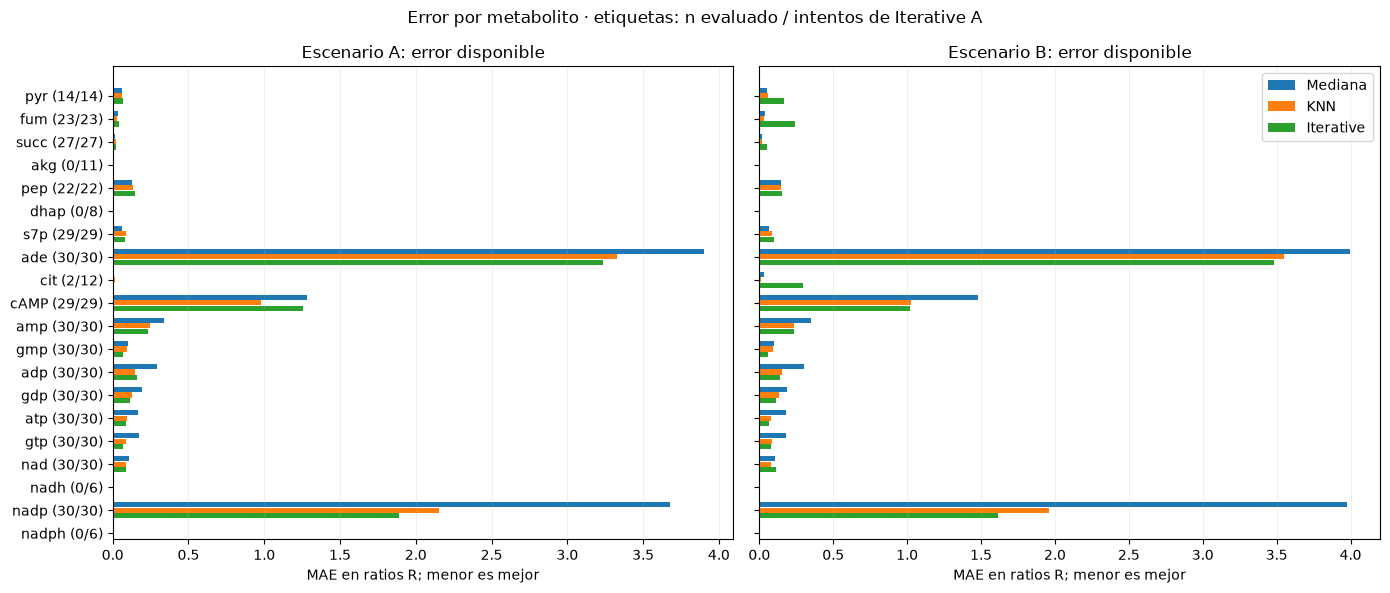

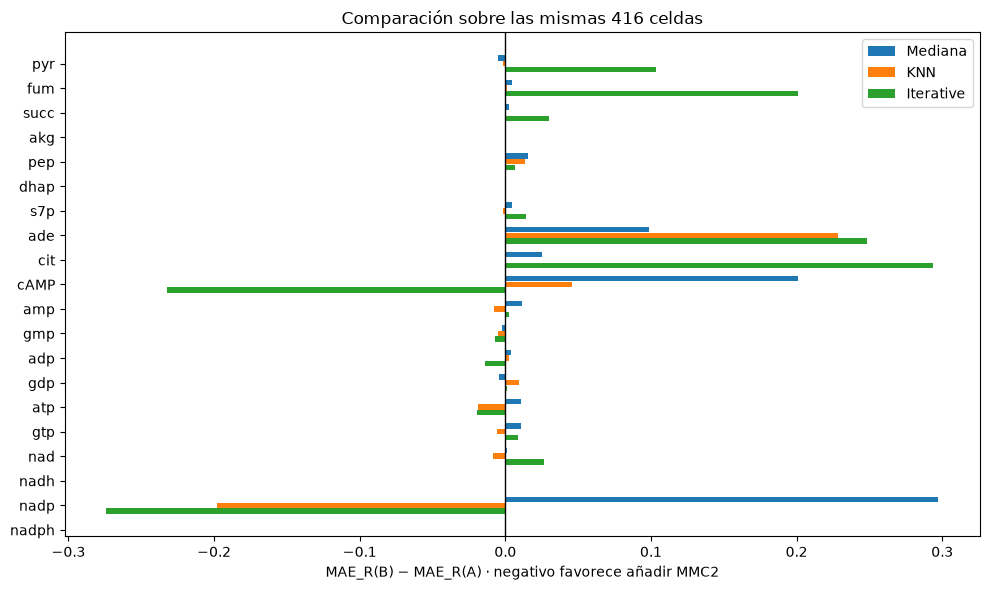

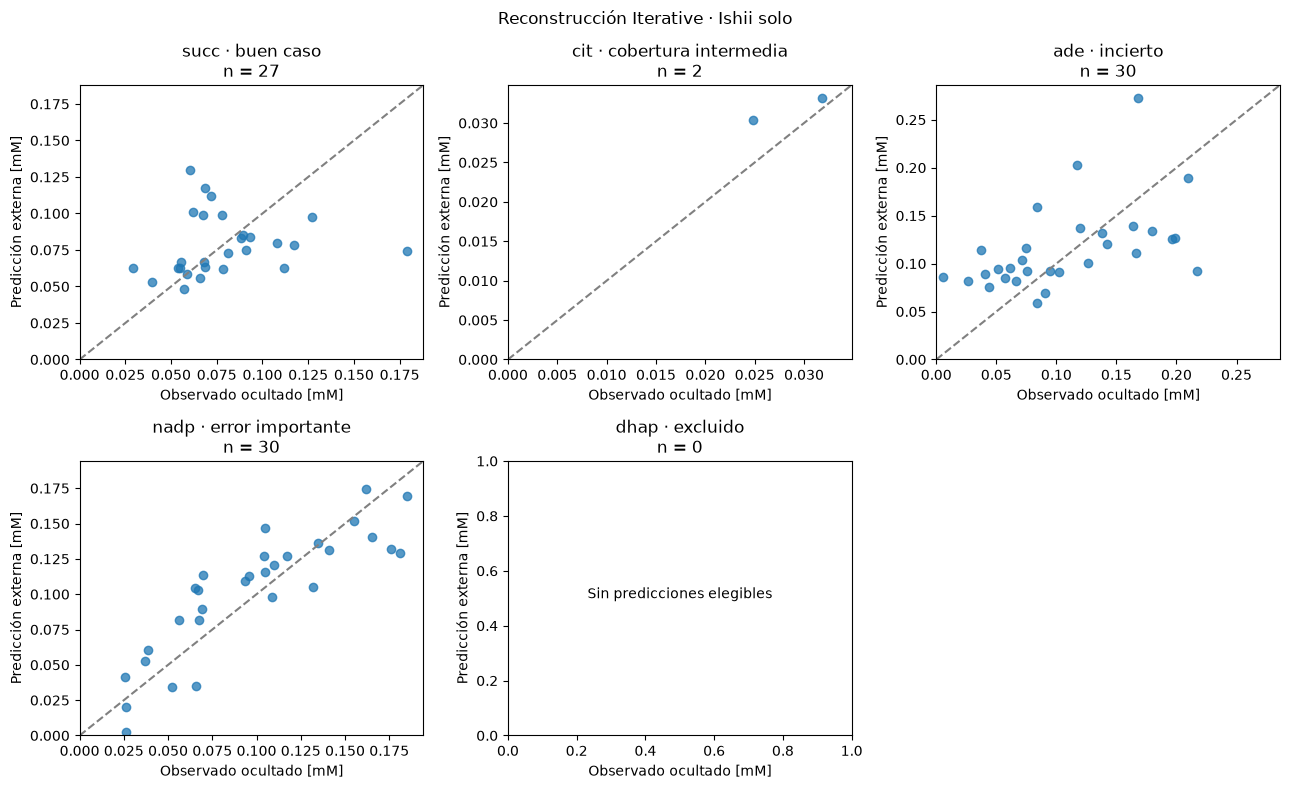

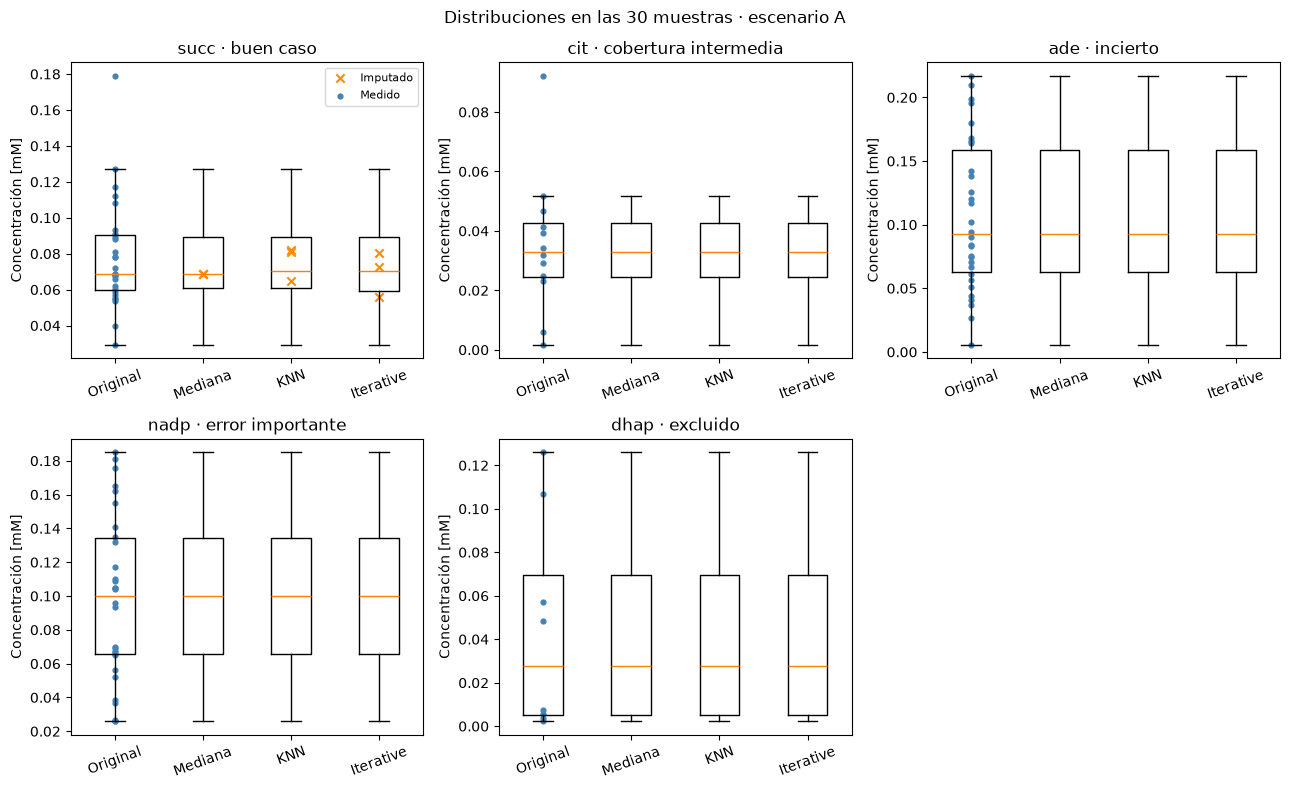

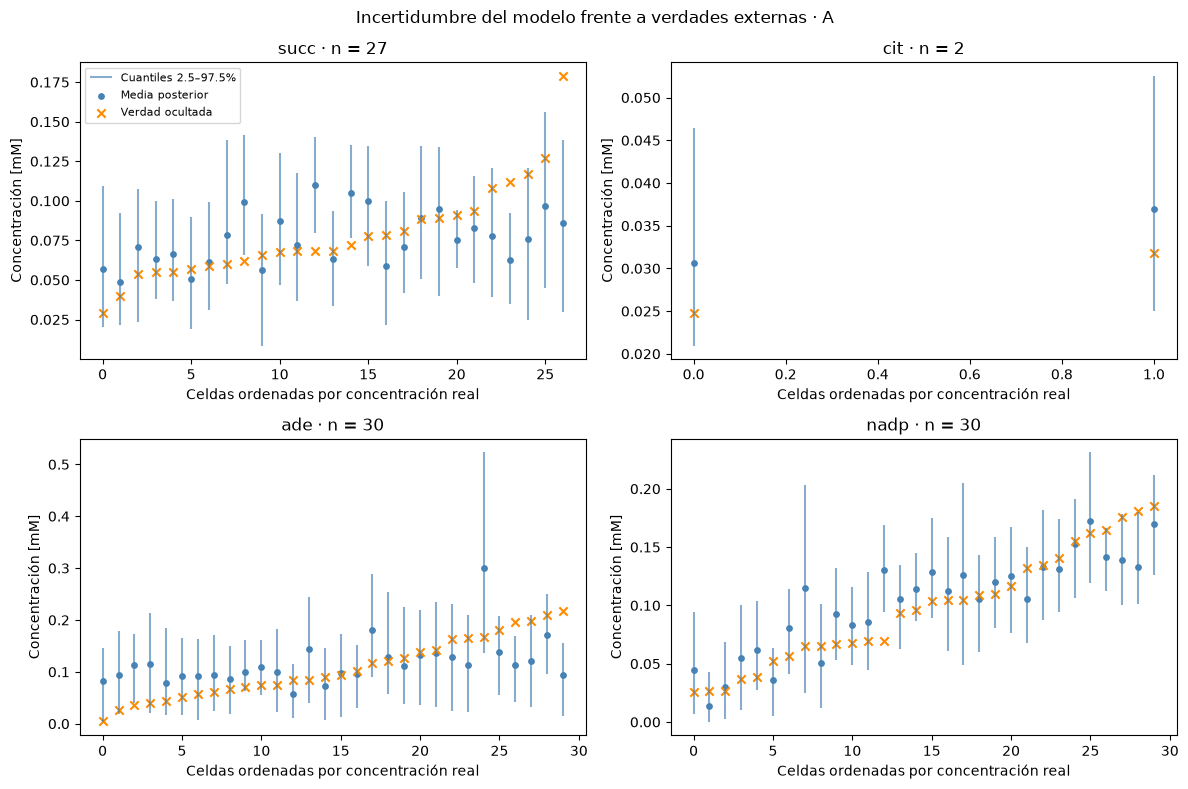

In [12]:
individual = metricas.query("nivel == 'metabolito' and alcance == 'disponibles'").copy()
perfil = individual.query("escenario == 'A' and metodo == 'Iterative'").set_index('metabolito')
anchuras = cobertura_intervalos.loc['A', 'amplitud_media_R']
elegidos = []
buenos = perfil[perfil.cobertura_pct.ge(80) & perfil.MAE_R.notna()]
bueno = buenos.MAE_R.idxmin()
elegidos.append(('buen caso', bueno, 'Cobertura ≥80%; menor MAE_R entre esos casos'))
intermedios = perfil[perfil.cobertura_pct.gt(0) & perfil.cobertura_pct.lt(100)].drop(index=[bueno], errors='ignore')
if intermedios.empty:
    intermedios = perfil[perfil.MAE_R.notna()].drop(index=[bueno])
intermedio = (intermedios.cobertura_pct - 50).abs().idxmin()
elegidos.append(('cobertura intermedia', intermedio, 'Cobertura más cercana a 50% entre casos restantes con predicción'))
usados = [m for _, m, _ in elegidos]
incierto = anchuras.drop(index=usados, errors='ignore').idxmax()
elegidos.append(('incierto', incierto, 'Mayor amplitud posterior media en R entre casos restantes'))
usados.append(incierto)
falla = perfil.drop(index=usados).MAE_R.idxmax()
elegidos.append(('error importante', falla, 'Mayor MAE_R de los casos restantes'))
elegidos.append(('excluido', 'dhap', 'Solo ocho mediciones Ishii; no supera elegibilidad'))
casos = pd.DataFrame(elegidos, columns=['perfil', 'metabolito', 'razon'])
casos.to_csv(SALIDA / 'casos_representativos.csv', index=False)
display(casos)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, escenario in zip(axes, ['A', 'B']):
    for desplazamiento, metodo in zip([-.23, 0, .23], METODOS):
        datos = individual.query('escenario == @escenario and metodo == @metodo').set_index('metabolito').reindex(ishii.columns)
        ax.barh(np.arange(20) + desplazamiento, datos.MAE_R, height=.22, label=metodo)
    etiquetas = [f'{m} ({int(perfil.at[m, "n_predicciones"])}/{int(perfil.at[m, "n_intentos"])})' for m in ishii.columns]
    ax.set_yticks(np.arange(20), etiquetas)
    ax.set_title(f'Escenario {escenario}: error disponible')
    ax.set_xlabel('MAE en ratios R; menor es mejor')
    ax.grid(axis='x', alpha=.2)
axes[0].invert_yaxis()
axes[1].legend()
fig.suptitle('Error por metabolito · etiquetas: n evaluado / intentos de Iterative A')
fig.tight_layout()
fig.savefig(SALIDA / 'figuras/01_error.png', dpi=160)
plt.show()

pareada = metricas.query("nivel == 'metabolito' and alcance == 'comunes_seis'")
fig, ax = plt.subplots(figsize=(10, 6))
for desplazamiento, metodo in zip([-.23, 0, .23], METODOS):
    cambio = pareada[pareada.metodo.eq(metodo)].pivot(index='metabolito', columns='escenario', values='MAE_R').reindex(ishii.columns)
    ax.barh(np.arange(20) + desplazamiento, cambio.B - cambio.A, height=.22, label=metodo)
ax.set_yticks(np.arange(20), ishii.columns)
ax.invert_yaxis()
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('MAE_R(B) − MAE_R(A) · negativo favorece añadir MMC2')
ax.set_title(f'Comparación sobre las mismas {len(celdas_comunes)} celdas')
ax.legend()
fig.tight_layout()
fig.savefig(SALIDA / 'figuras/02_aporte_mmc2.png', dpi=160)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, caso in zip(axes.flat, casos.itertuples()):
    datos = validacion.query("escenario == 'A' and metodo == 'Iterative' and metabolito == @caso.metabolito")
    datos = datos.dropna(subset=['pred_mM'])
    ax.set_title(f'{caso.metabolito} · {caso.perfil}\nn = {len(datos)}')
    if len(datos):
        ax.scatter(datos.verdad_mM, datos.pred_mM, alpha=.75)
        limite = max(datos.verdad_mM.max(), datos.pred_mM.max()) * 1.05
        ax.plot([0, limite], [0, limite], '--', color='gray')
        ax.set(xlim=(0, limite), ylim=(0, limite))
    else:
        ax.text(.5, .5, 'Sin predicciones elegibles', ha='center', transform=ax.transAxes)
    ax.set_xlabel('Observado ocultado [mM]')
    ax.set_ylabel('Predicción externa [mM]')
axes.flat[-1].axis('off')
fig.suptitle('Reconstrucción Iterative · Ishii solo')
fig.tight_layout()
fig.savefig(SALIDA / 'figuras/03_observado_predicho.png', dpi=160)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, caso in zip(axes.flat, casos.itertuples()):
    m = caso.metabolito
    valores = [ishii[m].dropna()] + [matrices[('A', metodo)][m].dropna() for metodo in METODOS]
    ax.boxplot(valores, tick_labels=['Original', 'Mediana', 'KNN', 'Iterative'], showfliers=False)
    for j, metodo in enumerate(METODOS, start=2):
        nuevos = matrices[('A', metodo)].loc[ishii[m].isna(), m].dropna()
        ax.scatter(np.full(len(nuevos), j), nuevos, marker='x', color='darkorange', label='Imputado' if j == 2 else None)
    ax.scatter(np.ones(ishii[m].count()), ishii[m].dropna(), s=12, color='steelblue', label='Medido')
    ax.set_title(f'{m} · {caso.perfil}')
    ax.set_ylabel('Concentración [mM]')
    ax.tick_params(axis='x', rotation=20)
axes.flat[-1].axis('off')
axes.flat[0].legend(fontsize=8)
fig.suptitle('Distribuciones en las 30 muestras · escenario A')
fig.tight_layout()
fig.savefig(SALIDA / 'figuras/04_distribuciones.png', dpi=160)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, caso in zip(axes.flat, casos.iloc[:4].itertuples()):
    datos = incertidumbre.query("etapa == 'externa' and escenario == 'A' and metabolito == @caso.metabolito and intervalo_disponible").sort_values('verdad_mM')
    # Mostrar todos los intervalos disponibles, ordenados por verdad para leer el sesgo.
    x = np.arange(len(datos))
    ax.vlines(x, datos.q025_mM, datos.q975_mM, color='steelblue', alpha=.65, label='Cuantiles 2.5–97.5%')
    ax.scatter(x, datos.media_mM, s=15, color='steelblue', label='Media posterior')
    ax.scatter(x, datos.verdad_mM, marker='x', color='darkorange', label='Verdad ocultada')
    ax.set_title(f'{caso.metabolito} · n = {len(datos)}')
    ax.set_xlabel('Celdas ordenadas por concentración real')
    ax.set_ylabel('Concentración [mM]')
axes.flat[0].legend(fontsize=8)
fig.suptitle('Incertidumbre del modelo frente a verdades externas · A')
fig.tight_layout()
fig.savefig(SALIDA / 'figuras/05_intervalos.png', dpi=160)
plt.show()

## 11. Controles y lectura final
Los resultados son una nueva ejecución, no una transcripción de los MAE anteriores. Se conservan las mediciones originales y la normalización; cambia la política de soporte y el universo evaluado. Por ello no se atribuyen diferencias frente al panel histórico exclusivamente a añadir metabolitos.

La validación oculta observaciones detectadas: los faltantes reales pueden deberse a límites analíticos y no ser aleatorios. No se garantiza igual error en esos huecos. MMC2 cambia carbono, cultivo y estudio; su aporte es una prueba de transferencia, no una réplica de Ishii. No se seleccionaron sus condiciones usando los valores de prueba. Los intervalos son condicionales al modelo y a una referencia fija; 30 sorteos no bastan para cuantiles muy precisos.

In [13]:
ajustes = pd.DataFrame(registro_ajustes)
posteriores = ajustes[ajustes.posterior]
for fila in posteriores.itertuples():
    assert fila.rondas == json.loads(fila.parametros)['max_iter']
assert len(posteriores) == 30 * 2 * 6
assert len(set(SEMILLAS_POSTERIOR)) == 30
pd.testing.assert_frame_equal(ishii, original)
for nombre, huella in huellas_entrada.items():
    assert hashlib.sha256((ENTRADA / nombre).read_bytes()).hexdigest() == huella
for (escenario, metodo), matriz in matrices.items():
    pd.testing.assert_frame_equal(matriz.where(ishii.notna()), ishii)
ajustes.to_csv(SALIDA / 'ajustes.csv', index=False)
pd.DataFrame(registro_elegibilidad).drop_duplicates().to_csv(SALIDA / 'elegibilidad_entrenamientos.csv', index=False)
pd.DataFrame(registro_busqueda).to_csv(SALIDA / 'busqueda_interna.csv', index=False)
pd.DataFrame(seleccionados).to_csv(SALIDA / 'parametros_seleccionados.csv', index=False)
versiones = {nombre: importlib.metadata.version(nombre) for nombre in
             ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'openpyxl', 'pypdf', 'ipython']}
verificacion = dict(
    python=platform.python_version(), versiones=versiones, semilla=SEMILLA,
    semillas_posterior=SEMILLAS_POSTERIOR, entradas_sha256=huellas_entrada,
    mascaras_sha256=hashlib.sha256(archivo_mascaras.read_bytes()).hexdigest(),
    protocolo='GroupKFold 5 externos / 3 internos; consulta individual; sin log',
    umbrales=dict(observaciones=10, grupos=5, pares=5, predictores=2,
                  donantes_knn=3, evaluadas_aplicacion=10, bloques_aplicacion=3),
    configuraciones=CONFIGURACIONES, bayesian_ridge=BayesianRidge().get_params(),
    n_intentos=len(externas), n_comunes_seis=len(celdas_comunes),
    n_ajustes_posteriores=len(posteriores), originales_intactos=True,
    fuentes_auditoria_intactas=True, mascaras_reproducidas=True,
)
(SALIDA / 'verificacion.json').write_text(json.dumps(verificacion, indent=2), encoding='utf-8')
principal = resumen_global.query("alcance == 'comunes_seis'")
print('Comparación principal (MAE_R macro, igual peso por metabolito):')
display(principal[['escenario', 'metodo', 'MAE_R_macro', 'MAE_mM_macro', 'n_predicciones', 'SD_MAE_R_macro_bloques']].round(4))
print('Advertencias de convergencia determinista:',
      int(ajustes.loc[~ajustes.posterior, 'aviso_convergencia'].sum()))
print('Revisar ajustes.csv: no se sustituyeron métodos que no convergieron.')

Comparación principal (MAE_R macro, igual peso por metabolito):


,escenario,metodo,MAE_R_macro,MAE_mM_macro,n_predicciones,SD_MAE_R_macro_bloques
6,A,Iterative,0.4713,0.0867,416,0.0842
7,A,KNN,0.4801,0.0910,416,0.1210
8,A,Mediana,0.6587,0.1216,416,0.1177
9,B,Iterative,0.4956,0.1207,416,0.1006
10,B,KNN,0.4835,0.0853,416,0.0907
11,B,Mediana,0.7009,0.1280,416,0.1307


Advertencias de convergencia determinista: 3
Revisar ajustes.csv: no se sustituyeron métodos que no convergieron.


## Resultados de esta ejecución

| Método | Ishii A | Ishii + MMC2 B |
|---|---:|---:|
| Mediana | 0.6682 | 0.6981 |
| KNN | 0.4964 | 0.4551 |
| Iterative | 0.4272 | 0.4715 |

MAE_R macro: igual peso por metabolito, sobre **413 celdas comunes de 457 intentos (90.4%)**, correspondientes a 17 compuestos. Incluye casos con pocas predicciones, que deben leerse junto con sus conteos.

1. **Menor error:** Iterative con Ishii solo (0.4272). En B el mejor es KNN (0.4551). Es una recomendación global exploratoria, no prueba de superioridad estadística.
2. **No se mantiene en todos los compuestos:** en A, Iterative tiene el menor MAE_R en 12 de 17, Mediana en 3 y KNN en 2. En B, Iterative/KNN ganan en ocho cada uno y Mediana en uno. No se selecciona retrospectivamente un método por compuesto para fabricar una mejora global.
3. **Disponibilidad y error:** no hay evidencia de que más mediciones garanticen menor error. ADE tiene 30 verdades y error elevado; AKG y citrato parecen fáciles con solo 2 y 3 predicciones, pero son evaluaciones muy incompletas. Piruvato recibe 8. La selección de celdas evaluables y la referencia de cada compuesto impiden interpretar esa asociación como causal.
4. **MMC2:** mejora KNN (0.4964 → 0.4551), empeora Iterative (0.4272 → 0.4715) y Mediana (0.6682 → 0.6981). En Iterative, fumarato pasa de 0.0375 a 0.2328 MAE_R. No se recomienda añadir MMC2 indiscriminadamente.
5. **Incertidumbre:** los tres mayores anchos medios normalizados de A son ade (12.5 R), nadp (7.74 R), cAMP (4.15 R). La cobertura empírica de los intervalos del 95% es 85.2% en A y 88.4% en B, entre 413 y 413 intervalos disponibles. No alcanzan el 95% nominal: muestran infracobertura en estas observaciones. Es una comprobación de calibración, no un certificado biológico. Los cuantiles se estiman con solo 30 sorteos.
6. **Abstenciones finales:** DHAP, NADH y NADPH no superan la elegibilidad; piruvato, AKG y citrato no alcanzan diez predicciones externas en tres bloques. Se completan 20 de los 143 huecos documentales con cada método/escenario; quedan 123 pendientes. Los huecos completados corresponden a cAMP (1), fum (7), pep (8), s7p (1), succ (3). Tener soporte no garantiza un error biológicamente aceptable; especialmente cAMP necesita cautela por su MAE_R elevado.
7. **Distribuciones:** en Iterative/A, cAMP: media 0.006889 → 0.006828 mM; SD 0.002765 → 0.002737 mM; fum: media 0.05927 → 0.06107 mM; SD 0.02175 → 0.02157 mM; pep: media 0.0824 → 0.08717 mM; SD 0.06176 → 0.0539 mM; s7p: media 0.3474 → 0.3389 mM; SD 0.5464 → 0.5389 mM; succ: media 0.07867 → 0.07778 mM; SD 0.03053 → 0.02922 mM. Los cambios describen la mezcla de mediciones y estimaciones. Una menor SD después de imputar no demuestra mejora.
8. **Limitaciones:** muestras pequeñas y grupos solapados entre entrenamientos, faltantes posiblemente censurados, heterogeneidad entre estudios, relaciones lineales, referencia externa tratada como fija y evaluación de ocultamiento individual. Hubo 0 ajustes deterministas con advertencia de convergencia; se conservan y están identificados, sin reemplazarlos por otro método.

Los cinco perfiles elegidos son: buen caso: succ; cobertura intermedia: pyr; incierto: ade; error importante: nadp; excluido: dhap.

MAE_R divide el error por la referencia fija de glucosa; no es el porcentaje de error respecto a cada observación. Un MAE_R alto puede coexistir con un error pequeño en mM si la referencia es pequeña.
